In [1]:
import sys, os
sys.path.append(os.path.abspath(os.path.join("..")))

In [2]:
import numpy as np
import sklearn
from sklearn.model_selection import train_test_split
from src.features import clean_and_preprocess_data
from src.models import MultipleLinearRegression
from src.models import evaluate_variant
from src.diagnostics import average_residual_spread_by_hour
from src.features import split_sets_tr_val

let us now keep our dataset as it is and then fit a model on it ! 
Keeping Registered and Casual t verify model's multicollinearity and why redundant feature affect our model! 

In [3]:
import pandas as pd

df = pd.read_csv("../data/hour.csv")

In [4]:
df = df.drop(columns=['instant', 'dteday'])
print(df.columns)
X = df.iloc[:, :14]
print(X.columns)
y = df.iloc[:, -1]
y

Index(['season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday',
       'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'casual',
       'registered', 'cnt'],
      dtype='object')
Index(['season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday',
       'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'casual',
       'registered'],
      dtype='object')


0         16
1         40
2         32
3         13
4          1
        ... 
17374    119
17375     89
17376     90
17377     61
17378     49
Name: cnt, Length: 17379, dtype: int64

I had to predict the cnt but i just included `registered` and `casual` those are the things i have to predict and i just kept it in my training model sorry!! 

In [18]:
X_train_full, y_train_full, X_test_full, y_test_full = train_test_split(X, y, test_size=0.2, shuffle=False)

## for X_val[hr] for residual plot

_, _,X_val, _ = split_sets_tr_val(X_train_full,y_train_full, feature_cols=X.columns)

hr_val_original = X_val['hr'].copy()

X = X.drop(columns=['temp'])
X_tr, y_tr_log, X_val, y_val_log = clean_and_preprocess_data(df, target_cols='cnt', feature_cols=X.columns)

In [19]:
metrics, summary, y_pred, y_val_true = evaluate_variant(X_tr, y_tr_log, X_val, y_val_log)

In [20]:
from IPython.display import display

display(metrics)
display(summary)

,MSE,MAE,RMSE,Val R2,Train R2,Adjusted_R2_Val,SSE,SST,SSM
0,0.36586,0.463198,0.604864,0.80448,0.81621,0.801915,1017.456875,5203.849792,4477.894786


,Beta Hat,Standard Error,t_stats,p_values,CI lower,CI upper
Intercept,2.508890,0.044637,56.206990,0.000000e+00,2.421394,2.596386
yr,0.621940,0.016399,37.924860,0.000000e+00,0.589795,0.654086
mnth,0.016509,0.003420,4.827957,1.397833e-06,0.009806,0.023212
holiday,-0.148462,0.035897,-4.135767,3.563792e-05,-0.218827,-0.078098
weekday,0.020950,0.002856,7.336224,2.349232e-13,0.015352,0.026547
workingday,-0.037605,0.012669,-2.968264,3.001276e-03,-0.062438,-0.012771
atemp,1.752907,0.054178,32.354731,0.000000e+00,1.646709,1.859105
hum,-0.206906,0.037958,-5.450930,5.118054e-08,-0.281310,-0.132502
windspeed,-0.193195,0.048566,-3.978013,6.993572e-05,-0.288392,-0.097997
season_2,0.345025,0.019142,18.024208,0.000000e+00,0.307503,0.382547


(2781,)


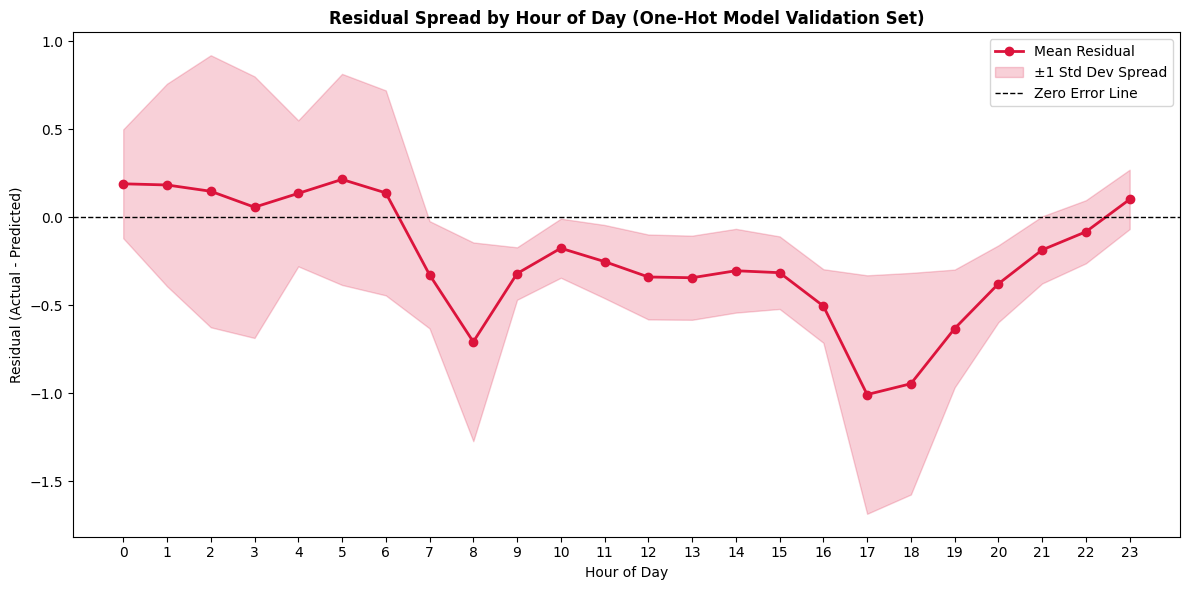

In [8]:


residual = y_val_true - y_pred
residual = np.ravel(residual)
print(residual.shape)
average_residual_spread_by_hour(hr_val_original, residual=residual)

using `registered` as y target

In [9]:
X.columns

Index(['season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday',
       'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'casual',
       'registered'],
      dtype='object')

In [16]:
X = X.iloc[:, :13]
print(X.columns)
X_train, y_train_log, X_val, y_val_log = clean_and_preprocess_data(df, target_cols='casual', feature_cols=X.columns)
X_train


metrics, summary, y_pred, y_val_true = evaluate_variant(X_train, y_train_log, X_val, y_val_log)
display(metrics)
display(summary)

Index(['season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday',
       'weathersit', 'temp', 'atemp', 'hum', 'windspeed'],
      dtype='object')


,MSE,MAE,RMSE,Val R2,Train R2,Adjusted_R2_Val,SSE,SST,SSM
0,0.439446,0.487887,0.662907,0.795091,0.793261,0.792327,1222.098057,5964.107457,4246.758439


,Beta Hat,Standard Error,t_stats,p_values,CI lower,CI upper
Intercept,0.837156,0.049771,16.820211,0.000000e+00,0.739597,0.934716
yr,0.394374,0.018064,21.832197,0.000000e+00,0.358966,0.429782
mnth,0.009628,0.003764,2.558196,1.053484e-02,0.002251,0.017005
holiday,-0.197520,0.039580,-4.990406,6.116754e-07,-0.275103,-0.119936
weekday,0.009792,0.003142,3.116393,1.835461e-03,0.003633,0.015951
workingday,-0.680826,0.013940,-48.839731,0.000000e+00,-0.708151,-0.653502
temp,0.676711,0.286348,2.363250,1.813263e-02,0.115419,1.238003
atemp,2.685896,0.310515,8.649820,0.000000e+00,2.077232,3.294559
hum,-0.426762,0.041801,-10.209484,0.000000e+00,-0.508698,-0.344825
windspeed,-0.362912,0.056612,-6.410556,1.508813e-10,-0.473881,-0.251943


In [17]:
X = X.iloc[:, :13]
print(X.columns)
X_train, y_train_log, X_val, y_val_log = clean_and_preprocess_data(df, target_cols='registered', feature_cols=X.columns)
X_train


metrics, summary, y_pred, y_val_true = evaluate_variant(X_train, y_train_log, X_val, y_val_log)
display(metrics)
display(summary)

Index(['season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday',
       'weathersit', 'temp', 'atemp', 'hum', 'windspeed'],
      dtype='object')


,MSE,MAE,RMSE,Val R2,Train R2,Adjusted_R2_Val,SSE,SST,SSM
0,0.371672,0.468577,0.609649,0.793707,0.804979,0.790924,1033.620921,5010.454499,4337.806708


,Beta Hat,Standard Error,t_stats,p_values,CI lower,CI upper
Intercept,2.346816,0.046027,50.988145,0.000000e+00,2.256595,2.437036
yr,0.651038,0.016705,38.972715,0.000000e+00,0.618293,0.683782
mnth,0.018418,0.003480,5.292036,1.232706e-07,0.011596,0.025241
holiday,-0.148812,0.036602,-4.065646,4.823056e-05,-0.220560,-0.077065
weekday,0.023863,0.002906,8.212162,2.220446e-16,0.018167,0.029559
workingday,0.110614,0.012891,8.580530,0.000000e+00,0.085345,0.135884
temp,0.881237,0.264806,3.327858,8.780149e-04,0.362170,1.400305
atemp,0.452596,0.287155,1.576138,1.150226e-01,-0.110279,1.015472
hum,-0.177710,0.038656,-4.597213,4.329145e-06,-0.253482,-0.101937
windspeed,-0.212603,0.052353,-4.060964,4.920681e-05,-0.315224,-0.109982
